# SpaceX capstone — completed answers

**Presenter: Hrant Ohannes Kasparian**

All requested computational tasks are answered below. Frozen IBM course datasets are included. Live API and historical Wikipedia access are unavailable; scraping code is complete but no scraped observations are claimed. Road/rail proximity locations are illustrative. Project repository: https://github.com/hrantk28-stack/SpaceX-Falcon9-Capstone.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, json, sqlite3
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
D=ROOT/'data'
SRC=ROOT/'source'
if not SRC.exists(): SRC=ROOT/'deliverables/source'
df=pd.read_csv(D/'dataset_part_2.csv')
X=pd.read_csv(D/'dataset_part_3.csv')
results=json.loads((D/'results.json').read_text())
print('Data:',df.shape,'Features:',X.shape)

Data: (90, 18) Features: (90, 83)


## API data collection audit
Use the archived API JSON; live endpoint returned HTTP 522. Full remote-enrichment design is explained in the report. The frozen model cohort must not be misrepresented as a freshly rebuilt live cohort.

In [2]:
archive=json.loads((D/'API_call_spacex_api.json').read_text())
api=pd.json_normalize(archive)
print('Archived launches:',len(api))
display(api['rocket'].value_counts())
print('Last archive launch date:',api.date_utc.max())

Archived launches: 107


rocket
5e9d0d95eda69973a809d1ec    99
5e9d0d95eda69955f709d1eb     5
5e9d0d95eda69974db09d1ed     3
Name: count, dtype: int64

Last archive launch date: 2020-11-16T00:27:00.000Z


## Web scraping — Tasks 1, 2 and 3
1. GET historical revision, check response, create BeautifulSoup and inspect title.
2. Match launch tables semantically and normalize header names.
3. Parse numbered launch rows, handle rowspans, clean annotations and export a DataFrame.

The source below solves the tasks. The requested Wikipedia page returned HTTP 403; therefore the scrape cannot be reported as completed execution.

In [3]:
import importlib.util
spec=importlib.util.spec_from_file_location('collection',SRC/'collection.py')
collection=importlib.util.module_from_spec(spec);spec.loader.exec_module(collection)
print('Scraper code (not executed here because the source returned HTTP 403):')
import inspect
print(inspect.getsource(collection.scrape_wikipedia))

Scraper code (not executed here because the source returned HTTP 403):
def scrape_wikipedia():
 # TASK 1 — GET and soup; fail explicitly on HTTP errors
 response=requests.get(WIKI,headers={'User-Agent':'Mozilla/5.0 (educational data-science project)'},timeout=30)
 response.raise_for_status();soup=BeautifulSoup(response.text,'html.parser')
 print('Page title:',soup.title.get_text(strip=True))
 tables=soup.find_all('table')
 # TASK 2 — match headers semantically, not a brittle table index
 wanted=[];column_names=[]
 for table in tables:
  header=table.find('tr');ths=header.find_all('th') if header else []
  names=[]
  for th in ths:
   th=BeautifulSoup(str(th),'html.parser')
   for ref in th.select('sup'):ref.decompose()
   names.append(re.sub(r'\s+',' ',th.get_text(' ',strip=True)).strip())
  if any('Flight' in x for x in names) and any('Payload mass' in x for x in names):
   wanted.append(table)
   if not column_names:column_names=names
 print('Column names:',column_names)
 # TASK 3 — 

## Data wrangling — initial checks

In [4]:
print(df.info())
display(pd.DataFrame({'missing':df.isna().sum(),'percent':df.isna().mean()*100}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
 17  Class           90 non-null     int64

,missing,percent
FlightNumber,0,0.000000
Date,0,0.000000
BoosterVersion,0,0.000000
PayloadMass,0,0.000000
Orbit,0,0.000000
LaunchSite,0,0.000000
Outcome,0,0.000000
Flights,0,0.000000
GridFins,0,0.000000
Reused,0,0.000000


### Task 1 — Launch count per site

In [5]:
display(df['LaunchSite'].value_counts())

LaunchSite
CCAFS SLC 40    55
KSC LC 39A      22
VAFB SLC 4E     13
Name: count, dtype: int64

### Task 2 — Orbit frequency, excluding GTO as explicitly requested
The full 90-row data are retained for EDA and ML; the non-GTO count table totals 63.

In [6]:
display(df.loc[df.Orbit!='GTO','Orbit'].value_counts())
print('Non-GTO launches:',df.Orbit.ne('GTO').sum())

Orbit
ISS      21
VLEO     14
PO        9
LEO       7
SSO       5
MEO       3
HEO       1
ES-L1     1
SO        1
GEO       1
Name: count, dtype: int64

Non-GTO launches: 63


### Task 3 — Landing-outcome occurrences

In [7]:
landing_outcomes=df['Outcome'].value_counts()
display(landing_outcomes)

Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64

### Task 4 — Landing label
True Ocean is positive in the course definition but does not imply recovery or reuse.

In [8]:
bad_outcome={'False Ocean','False RTLS','False ASDS','None ASDS','None None'}
landing_class=[0 if v in bad_outcome else 1 for v in df['Outcome']]
assert np.array_equal(landing_class,df.Class)
print('Positive:',sum(landing_class),'Negative:',len(landing_class)-sum(landing_class))
print('Success rate:',np.mean(landing_class))

Positive: 60 Negative: 30
Success rate: 0.6666666666666666


## EDA — Tasks 1–6

### Task 1: Flight number × launch site
Later flights tend toward success; site and calendar-time effects are confounded.

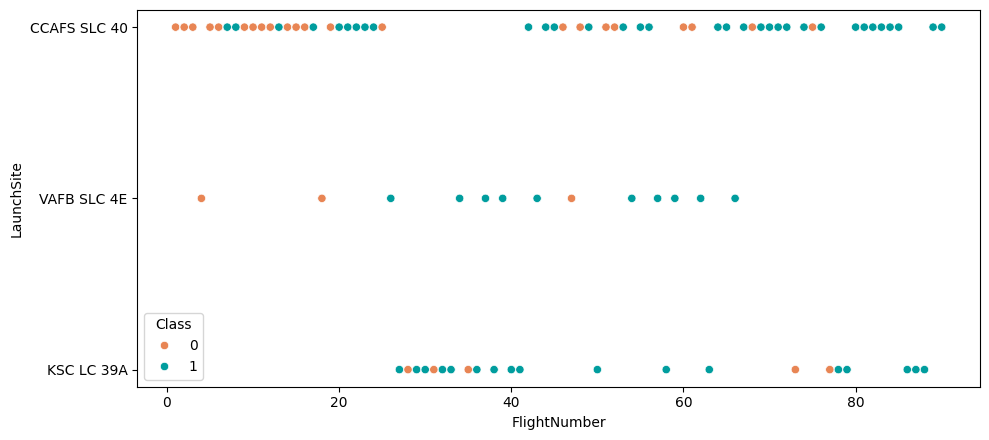

In [9]:
plt.figure(figsize=(10,4.5))
sns.scatterplot(data=df,x='FlightNumber',y='LaunchSite',hue='Class',palette={0:'#E88554',1:'#009D9E'})
plt.tight_layout();plt.show()

### Task 2: Payload × launch site
VAFB has no payload above 10,000 kg; its observed maximum is 9,600 kg.

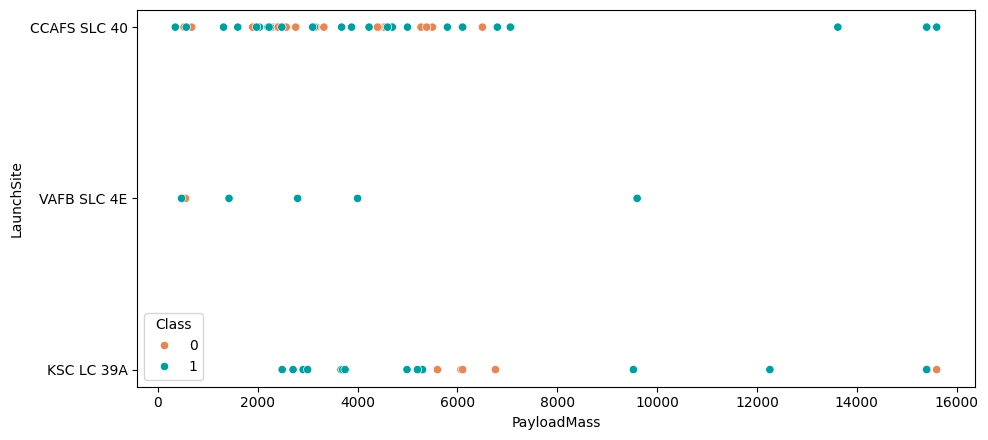

In [10]:
plt.figure(figsize=(10,4.5))
sns.scatterplot(data=df,x='PayloadMass',y='LaunchSite',hue='Class',palette={0:'#E88554',1:'#009D9E'})
plt.tight_layout();plt.show()

### Task 4: Flight number × orbit
LEO improves with flight sequence; GTO remains mixed.

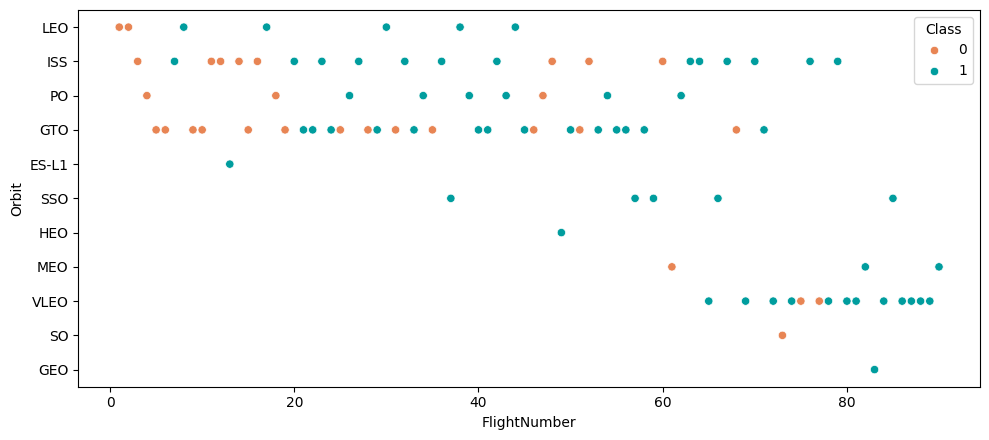

In [11]:
plt.figure(figsize=(10,4.5))
sns.scatterplot(data=df,x='FlightNumber',y='Orbit',hue='Class',palette={0:'#E88554',1:'#009D9E'})
plt.tight_layout();plt.show()

### Task 5: Payload × orbit
Payload alone does not separate outcomes; GTO classes overlap.

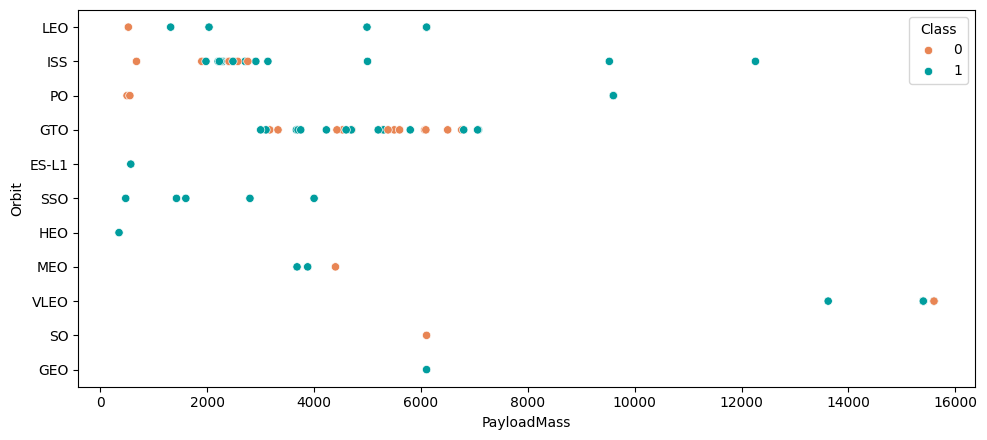

In [12]:
plt.figure(figsize=(10,4.5))
sns.scatterplot(data=df,x='PayloadMass',y='Orbit',hue='Class',palette={0:'#E88554',1:'#009D9E'})
plt.tight_layout();plt.show()

### Task 3 — Orbit success bar chart
SSO is 5/5. ES-L1, GEO and HEO are each 1/1. Show sample sizes; these perfect rates do not imply certainty.

,mean,count,sum
Orbit,,,
ES-L1,1.000000,1,1
GEO,1.000000,1,1
GTO,0.518519,27,14
HEO,1.000000,1,1
ISS,0.619048,21,13
LEO,0.714286,7,5
MEO,0.666667,3,2
PO,0.666667,9,6
SO,0.000000,1,0


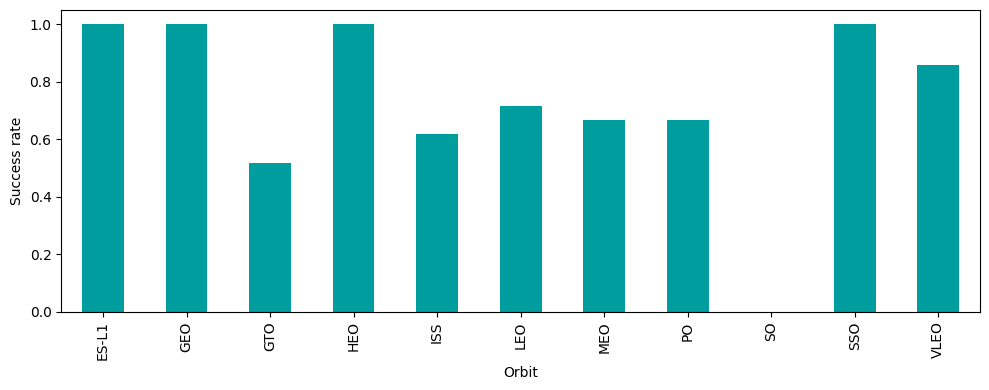

In [13]:
orbit=df.groupby('Orbit').Class.agg(['mean','count','sum'])
display(orbit)
orbit['mean'].plot.bar(color='#009D9E',ylabel='Success rate',figsize=(10,4))
plt.tight_layout();plt.show()

### Task 6 — Yearly trend
The notebook’s monotonic-improvement statement is wrong: 2018 and 2020 decline relative to the prior observed year.

,count,sum,mean
Date,,,
2010,1,0,0.000000
2012,1,0,0.000000
2013,3,0,0.000000
2014,6,2,0.333333
2015,6,2,0.333333
2016,8,5,0.625000
2017,18,15,0.833333
2018,18,11,0.611111
2019,10,9,0.900000


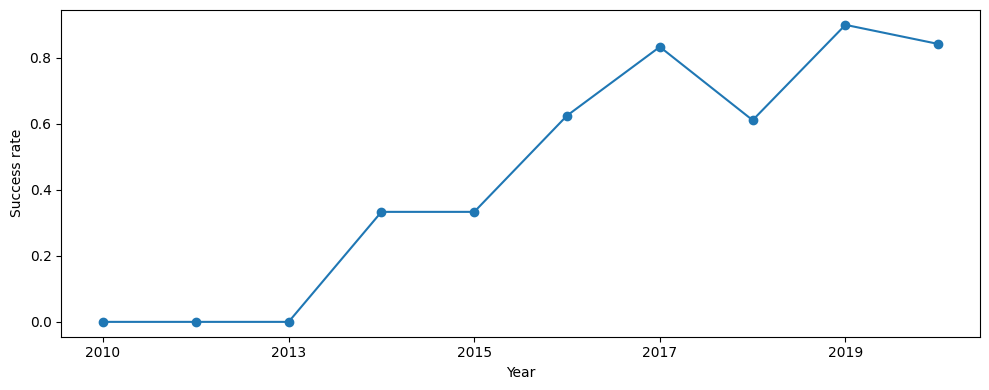

In [14]:
yearly=df.groupby(df.Date.str[:4]).Class.agg(['count','sum','mean'])
display(yearly)
yearly['mean'].plot(marker='o',figsize=(10,4),ylabel='Success rate',xlabel='Year')
plt.tight_layout();plt.show()

### Tasks 7–8 — Dummy variables and float64 conversion

In [15]:
features=df[['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']]
features_one_hot=pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial','GridFins','Reused','Legs']).astype('float64')
display(features_one_hot.head())
print('Shape:',features_one_hot.shape)
print('Every column float64:',features_one_hot.dtypes.eq('float64').all())
assert set(features_one_hot.columns)==set(X.columns)
assert np.allclose(features_one_hot[X.columns],X)

,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,Orbit_GTO,Orbit_HEO,Orbit_ISS,...,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062,GridFins_False,GridFins_True,Reused_False,Reused_True,Legs_False,Legs_True
0,1.0,6104.959412,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,2.0,525.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,3.0,677.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,4.0,500.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,5.0,3170.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


Shape: (90, 83)
Every column float64: True


## SQL — Tasks 1–10
Trim text whitespace; retain distinct site names. Task 4 uses the v1.1 family prefix. Task 7 groups all Success-prefixed mission labels.

In [16]:
sql=pd.read_csv(D/'Spacex.csv').map(lambda x:x.strip() if isinstance(x,str) else x)
conn=sqlite3.connect(':memory:')
sql.to_sql('SPACEXTBL',conn,index=False,if_exists='replace')

101

### SQL Task 1

In [17]:
query = 'SELECT DISTINCT Launch_Site FROM SPACEXTBL ORDER BY Launch_Site;'
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,Launch_Site
0,CCAFS LC-40
1,CCAFS SLC-40
2,KSC LC-39A
3,VAFB SLC-4E


### SQL Task 2

In [18]:
query = "SELECT * FROM SPACEXTBL WHERE Launch_Site LIKE 'CCA%' ORDER BY Date LIMIT 5;"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of Brouere cheese",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


### SQL Task 3

In [19]:
query = "SELECT SUM(PAYLOAD_MASS__KG_) AS total_kg FROM SPACEXTBL WHERE Customer = 'NASA (CRS)';"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,total_kg
0,45596


### SQL Task 4

In [20]:
query = "SELECT AVG(PAYLOAD_MASS__KG_) AS average_kg FROM SPACEXTBL WHERE Booster_Version LIKE 'F9 v1.1%';"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,average_kg
0,2534.666667


### SQL Task 5

In [21]:
query = "SELECT MIN(Date) AS first_ground_landing FROM SPACEXTBL WHERE Landing_Outcome = 'Success (ground pad)';"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,first_ground_landing
0,2015-12-22


### SQL Task 6

In [22]:
query = "SELECT DISTINCT Booster_Version FROM SPACEXTBL WHERE Landing_Outcome = 'Success (drone ship)' AND PAYLOAD_MASS__KG_ > 4000 AND PAYLOAD_MASS__KG_ < 6000;"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,Booster_Version
0,F9 FT B1022
1,F9 FT B1026
2,F9 FT B1021.2
3,F9 FT B1031.2


### SQL Task 7

In [23]:
query = "SELECT CASE WHEN Mission_Outcome LIKE 'Success%' THEN 'Success' ELSE 'Failure' END AS mission_result, COUNT(*) AS launches FROM SPACEXTBL GROUP BY mission_result;"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,mission_result,launches
0,Failure,1
1,Success,100


### SQL Task 8

In [24]:
query = 'SELECT DISTINCT Booster_Version, PAYLOAD_MASS__KG_ FROM SPACEXTBL WHERE PAYLOAD_MASS__KG_ = (SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTBL);'
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,Booster_Version,PAYLOAD_MASS__KG_
0,F9 B5 B1048.4,15600
1,F9 B5 B1049.4,15600
2,F9 B5 B1051.3,15600
3,F9 B5 B1056.4,15600
4,F9 B5 B1048.5,15600
5,F9 B5 B1051.4,15600
6,F9 B5 B1049.5,15600
7,F9 B5 B1060.2,15600
8,F9 B5 B1058.3,15600
9,F9 B5 B1051.6,15600


### SQL Task 9

In [25]:
query = "SELECT CASE substr(Date,6,2) WHEN '01' THEN 'January' WHEN '02' THEN 'February' WHEN '03' THEN 'March' WHEN '04' THEN 'April' WHEN '05' THEN 'May' WHEN '06' THEN 'June' WHEN '07' THEN 'July' WHEN '08' THEN 'August' WHEN '09' THEN 'September' WHEN '10' THEN 'October' WHEN '11' THEN 'November' WHEN '12' THEN 'December' END AS month, Landing_Outcome, Booster_Version, Launch_Site FROM SPACEXTBL WHERE substr(Date,1,4) = '2015' AND Landing_Outcome = 'Failure (drone ship)' ORDER BY Date;"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,month,Landing_Outcome,Booster_Version,Launch_Site
0,January,Failure (drone ship),F9 v1.1 B1012,CCAFS LC-40
1,April,Failure (drone ship),F9 v1.1 B1015,CCAFS LC-40


### SQL Task 10

In [26]:
query = "SELECT Landing_Outcome, COUNT(*) AS launches, DENSE_RANK() OVER (ORDER BY COUNT(*) DESC) AS rank FROM SPACEXTBL WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY launches DESC, Landing_Outcome;"
answer=pd.read_sql_query(query,conn)
with pd.option_context("display.max_colwidth",None,"display.max_rows",100,"display.max_columns",20):
    display(answer)

,Landing_Outcome,launches,rank
0,No attempt,10,1
1,Failure (drone ship),5,2
2,Success (drone ship),5,2
3,Controlled (ocean),3,3
4,Success (ground pad),3,3
5,Failure (parachute),2,4
6,Uncontrolled (ocean),2,4
7,Precluded (drone ship),1,5


## Folium — Tasks 1–3
Task 1: mark sites; Task 2: green/red clustered launch records; Task 3: MousePosition, haversine distances and connecting lines. Complete executable map generation is in analyze.py. The geographic input uses four labels for three physical launch complexes; no coordinates are independently surveyed here.

In [27]:
geo=pd.read_csv(D/'spacex_launch_geo.csv')
display(geo[['Launch Site','Lat','Long']].drop_duplicates())
display(geo.groupby('Launch Site')['class'].agg(['count','sum','mean']))
print('Sites are not equatorial:',geo.Lat.min(),geo.Lat.max())
display(pd.DataFrame(results['proximity']).T)
print('Road/rail point identities are illustrative and unverified—not nearest-feature distances.')

,Launch Site,Lat,Long
0,CCAFS LC-40,28.562302,-80.577356
26,VAFB SLC-4E,34.632834,-120.610745
36,KSC LC-39A,28.573255,-80.646895
49,CCAFS SLC-40,28.563197,-80.576820


,count,sum,mean
Launch Site,,,
CCAFS LC-40,26,7,0.269231
CCAFS SLC-40,7,3,0.428571
KSC LC-39A,13,10,0.769231
VAFB SLC-4E,10,4,0.400000


Sites are not equatorial: 28.56230197 34.63283416


,lat,lon,distance_km
Atlantic coastline (sample point),28.56367,-80.57163,0.579712
Rail corridor (sample point),28.57200,-80.58500,1.311951
Road corridor (sample point),28.56200,-80.58300,0.552402
Titusville center (reference),28.61220,-80.80760,23.162649


Road/rail point identities are illustrative and unverified—not nearest-feature distances.


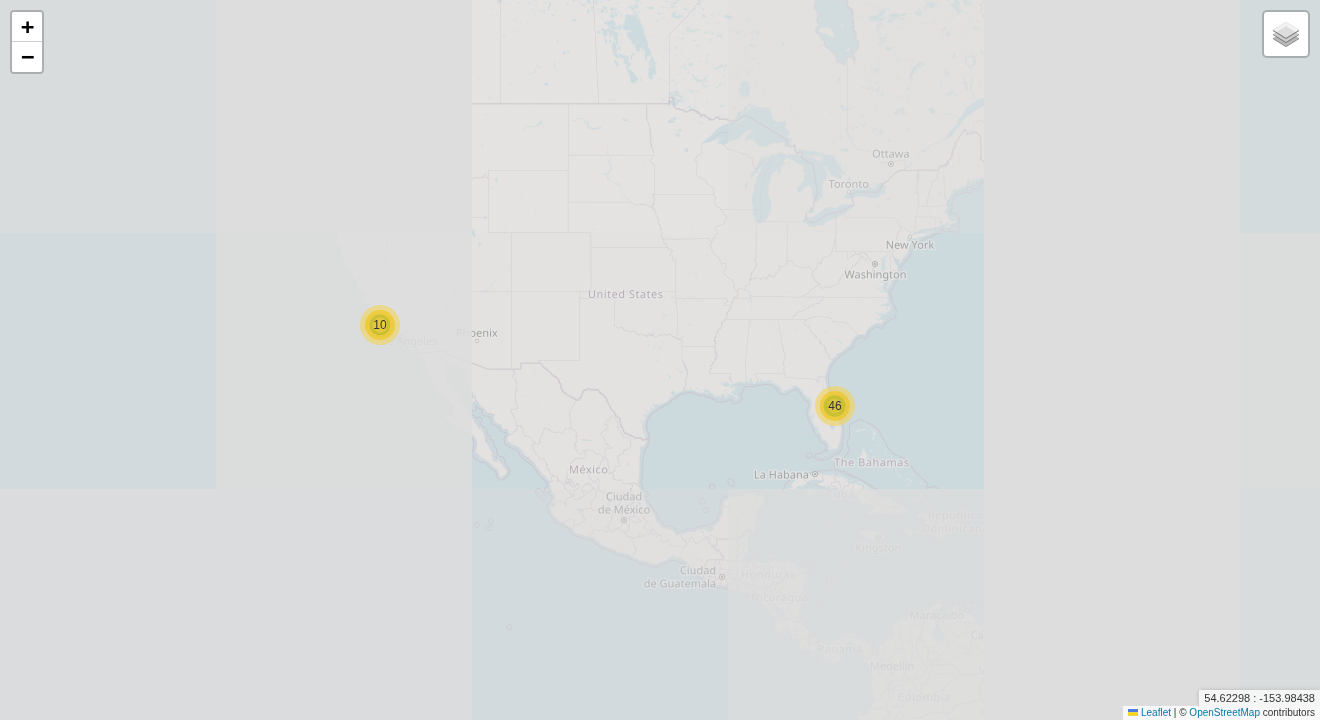

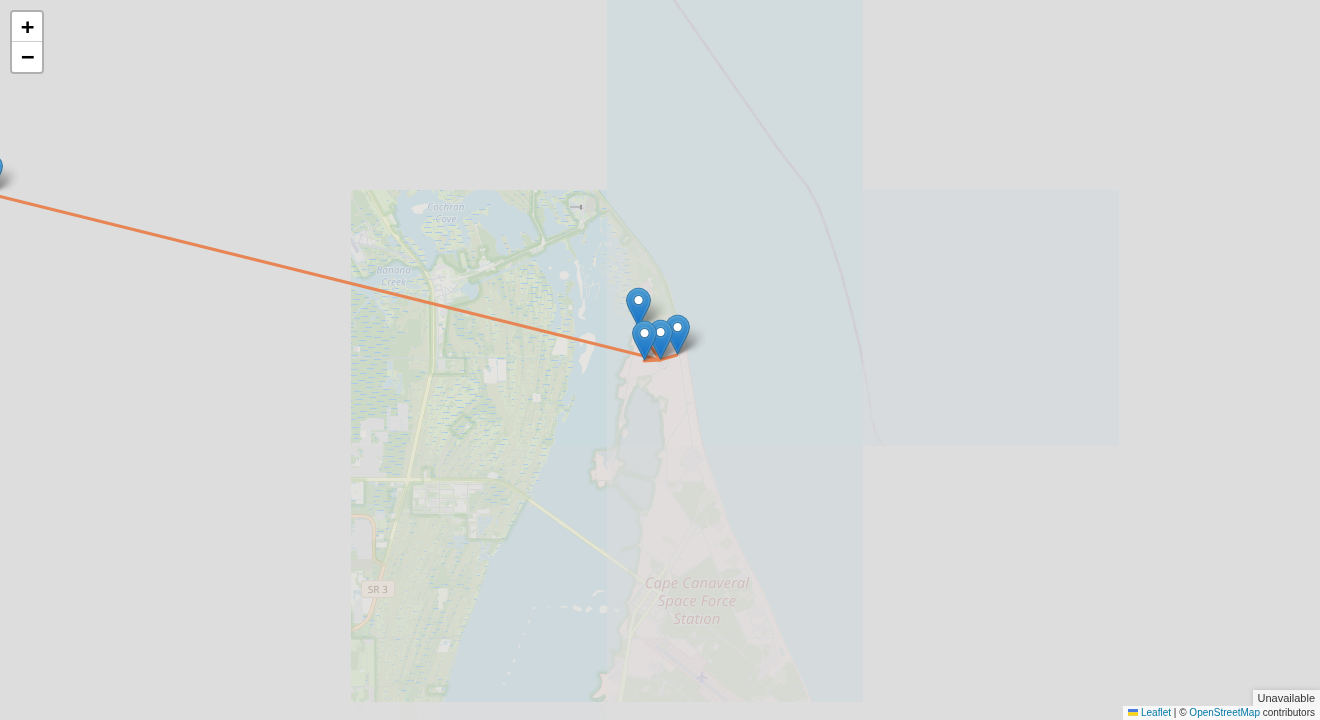

In [28]:
display(Image(filename=str(ROOT/'charts/launch_map.png')))
display(Image(filename=str(ROOT/'charts/proximity_map.png')))

## Dash — Tasks 1–4
The source includes a searchable All Sites dropdown, pie callback, 0–10,000 kg RangeSlider and joint-filter scatter callback. Run the app from a terminal rather than blocking this notebook.

In [29]:
print((SRC/'dashboard.py').read_text())

"""Run: python dashboard.py (datasets are included beside this source directory)."""
from pathlib import Path
import pandas as pd
from dash import Dash,dcc,html,Input,Output
import plotly.express as px
p=Path(__file__).resolve().parent.parent/'data'/'spacex_launch_dash.csv'
if not p.exists():p=Path(__file__).resolve().parents[2]/'data'/'spacex_launch_dash.csv'
df=pd.read_csv(p)
app=Dash(__name__)
app.layout=html.Div(style={'fontFamily':'Arial','background':'#F3F6FA','padding':'28px'},children=[
 html.H1('SpaceX | Launch outcome explorer',style={'color':'#153450'}),
 html.P('Historical course dataset • 56 launches • class 1 = successful landing'),
 dcc.Dropdown(id='site-dropdown',options=[{'label':'All Sites','value':'ALL'}]+[{'label':s,'value':s} for s in sorted(df['Launch Site'].unique())],value='ALL',placeholder='Select a Launch Site here',searchable=True),
 dcc.Graph(id='success-pie-chart'),html.H3('Payload range (kg)'),
 dcc.RangeSlider(id='payload-slider',min=0,max=10000,step=1000

### Dashboard questions 1–5
1. Most successes: KSC LC-39A, 10.
2. Highest rate: KSC LC-39A, 10/13 = 76.9%.
3. Highest 1,000 kg payload bin: (3,000, 4,000], 8/11 = 72.7%.
4. Lowest nonempty bin: (6,000, 7,000], 0/4.
5. Highest booster rate: B5, 1/1; FT leads among groups with n≥5, 16/24 = 66.7%.

In [30]:
dash_data=pd.read_csv(D/'spacex_launch_dash.csv')
display(dash_data.groupby('Launch Site')['class'].agg(['count','sum','mean']))
display(dash_data.groupby('Booster Version Category')['class'].agg(['count','sum','mean']))
dash_data['bin']=pd.cut(dash_data['Payload Mass (kg)'],range(0,10001,1000),include_lowest=True)
display(dash_data.groupby('bin',observed=False)['class'].agg(['count','sum','mean']))

,count,sum,mean
Launch Site,,,
CCAFS LC-40,26,7,0.269231
CCAFS SLC-40,7,3,0.428571
KSC LC-39A,13,10,0.769231
VAFB SLC-4E,10,4,0.400000


,count,sum,mean
Booster Version Category,,,
B4,11,6,0.545455
B5,1,1,1.000000
FT,24,16,0.666667
v1.0,5,0,0.000000
v1.1,15,1,0.066667


,count,sum,mean
bin,,,
"(-0.001, 1000.0]",10,2,0.200000
"(1000.0, 2000.0]",3,1,0.333333
"(2000.0, 3000.0]",10,5,0.500000
"(3000.0, 4000.0]",11,8,0.727273
"(4000.0, 5000.0]",8,3,0.375000
"(5000.0, 6000.0]",5,2,0.400000
"(6000.0, 7000.0]",4,0,0.000000
"(7000.0, 8000.0]",0,0,NaN
"(8000.0, 9000.0]",0,0,NaN


## Machine learning — Tasks 1–3
Select Class as a Series, then convert to a 1D NumPy array. The course protocol scales before splitting; the preferred protocol puts the scaler in each CV training fold.

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,precision_score,recall_score,f1_score
Y=df['Class'].to_numpy()
transform=StandardScaler()
X_scaled=transform.fit_transform(X)
X_train,X_test,Y_train,Y_test=train_test_split(X_scaled,Y,test_size=.2,random_state=2)
print(X_train.shape,X_test.shape,Y_train.shape,Y_test.shape)

(72, 83) (18, 83) (72,) (18,)


### Tasks 4–11 — Full cross-validation code
The following runs all four grids twice (course reproduction and fold-safe scaling), then prints each task’s CV settings, test accuracy and confusion matrix. The supplied legacy tree “auto” option is replaced by its equivalent “sqrt” and random_state=2 is added for reproducibility. This may produce different tree results from an unseeded older environment.

In [32]:
models={
'Logistic regression':(LogisticRegression(max_iter=2000),{'C':[.01,.1,1],'penalty':['l2'],'solver':['lbfgs']}),
'SVM':(SVC(),{'kernel':['linear','rbf','poly','rbf','sigmoid'],'C':np.logspace(-3,3,5),'gamma':np.logspace(-3,3,5)}),
'Decision tree':(DecisionTreeClassifier(random_state=2),{'criterion':['gini','entropy'],'splitter':['best','random'],'max_depth':list(range(2,20,2)),'max_features':['sqrt'],'min_samples_leaf':[1,2,4],'min_samples_split':[2,5,10]}),
'KNN':(KNeighborsClassifier(),{'n_neighbors':list(range(1,11)),'algorithm':['auto','ball_tree','kd_tree','brute'],'p':[1,2]})}
# Two runs: course reproduction and leakage-safe sensitivity
fresh_models=[];preds={}
for mode in ['Course reproduction','Fold-safe scaling']:
 xx=StandardScaler().fit_transform(X) if mode=='Course reproduction' else X
 a,b,c,d=train_test_split(xx,Y,test_size=.2,random_state=2)
 for name,(est,grid) in models.items():
  if mode=='Fold-safe scaling':
   est=Pipeline([('scale',StandardScaler()),('model',est)]);grid={'model__'+k:v for k,v in grid.items()}
  g=GridSearchCV(est,grid,cv=10,n_jobs=2,scoring='accuracy',error_score='raise');g.fit(a,c);p=g.predict(b)
  r={'mode':mode,'model':name,'cv_accuracy':float(g.best_score_),'test_accuracy':float(accuracy_score(d,p)),'precision':float(precision_score(d,p,zero_division=0)),'recall':float(recall_score(d,p)),'f1':float(f1_score(d,p)),'params':g.best_params_,'cm':confusion_matrix(d,p).tolist()};fresh_models.append(r);print(r,flush=True)
  if mode=='Fold-safe scaling':preds[name]=(d,p)


{'mode': 'Course reproduction', 'model': 'Logistic regression', 'cv_accuracy': 0.8464285714285713, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Course reproduction', 'model': 'SVM', 'cv_accuracy': 0.8482142857142856, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Course reproduction', 'model': 'Decision tree', 'cv_accuracy': 0.8767857142857143, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'splitter': 'best'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Course reproduction', 'model': 'KNN', 'cv_accuracy': 0.8482142857142858, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Fold-safe scaling', 'model': 'Logistic regression', 'cv_accuracy': 0.8464285714285713, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'model__C': 0.01, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Fold-safe scaling', 'model': 'SVM', 'cv_accuracy': 0.8214285714285714, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'model__C': np.float64(0.03162277660168379), 'model__gamma': np.float64(0.001), 'model__kernel': 'linear'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Fold-safe scaling', 'model': 'Decision tree', 'cv_accuracy': 0.8767857142857143, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'model__criterion': 'gini', 'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__splitter': 'best'}, 'cm': [[3, 3], [0, 12]]}


{'mode': 'Fold-safe scaling', 'model': 'KNN', 'cv_accuracy': 0.8482142857142858, 'test_accuracy': 0.8333333333333334, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888, 'params': {'model__algorithm': 'auto', 'model__n_neighbors': 10, 'model__p': 1}, 'cm': [[3, 3], [0, 12]]}


### Task 12 — Best method
All four methods tie on test accuracy (83.3%). Decision tree leads CV (87.68%) and is the provisional CV-selected model. The test set does not establish a unique best method. Every model has TN=3, FP=3, FN=0, TP=12. This means half of actual non-successes are incorrectly predicted as successful.

In [33]:
display(pd.DataFrame(fresh_models)[['mode','model','cv_accuracy','test_accuracy','precision','recall','f1']])
for name,(actual,pred) in preds.items():
    print(name,confusion_matrix(actual,pred).tolist())
print('Test majority baseline:',max(np.bincount(Y_test))/len(Y_test))

,mode,model,cv_accuracy,test_accuracy,precision,recall,f1
0,Course reproduction,Logistic regression,0.846429,0.833333,0.8,1.0,0.888889
1,Course reproduction,SVM,0.848214,0.833333,0.8,1.0,0.888889
2,Course reproduction,Decision tree,0.876786,0.833333,0.8,1.0,0.888889
3,Course reproduction,KNN,0.848214,0.833333,0.8,1.0,0.888889
4,Fold-safe scaling,Logistic regression,0.846429,0.833333,0.8,1.0,0.888889
5,Fold-safe scaling,SVM,0.821429,0.833333,0.8,1.0,0.888889
6,Fold-safe scaling,Decision tree,0.876786,0.833333,0.8,1.0,0.888889
7,Fold-safe scaling,KNN,0.848214,0.833333,0.8,1.0,0.888889


Logistic regression [[3, 3], [0, 12]]
SVM [[3, 3], [0, 12]]
Decision tree [[3, 3], [0, 12]]
KNN [[3, 3], [0, 12]]
Test majority baseline: 0.6666666666666666


## Conclusions and remaining limitations
The data support association, not site-selection causality. Temporal/grouped validation, prelaunch-feature auditing, probability calibration and false-positive-aware decision thresholds are needed. True Ocean counts as positive but is not evidence of reusable recovery. A two-stage attempt/strategy-then-success model would better separate capability from mission choice.

**Before submission:** rerun the blocked historical scrape; validate nearest railway/highway feature locations. The report transparently identifies these remaining limitations.